# Week 5 Part F ? Bonus normalized map on public data

## COVID-19 confirmed cases per million residents by country

This notebook uses two real public sources:

1. **Data:** Our World in Data, *COVID-19 dataset*, cumulative confirmed cases and population, downloaded from the maintained OWID GitHub CSV endpoint on **2026-10-25**.
2. **Boundaries:** Natural Earth, *Admin 0 countries, 1:110m*, GeoJSON from the `natural-earth-vector` repository, downloaded on **2026-10-25**.

The geographic key is ISO alpha-3 (`iso_code` in OWID and `ISO_A3` in Natural Earth). The mapped measure is `total_cases / population * 1,000,000`, so it is a population-normalized rate rather than a raw count.


In [1]:
from pathlib import Path
from datetime import date
from io import StringIO
import json, math
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.cm import ScalarMappable

BASE=Path.cwd()
if not (BASE/'Task6.ipynb').exists() and (BASE/'Week5').exists(): BASE=BASE/'Week5'
DOWNLOAD_DATE='2026-10-25'
OWID_URL='https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv'
NE_URL='https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson'

def download(url,path):
    if not path.exists():
        print('Downloading',url)
        urllib.request.urlretrieve(url,path)
    return path

owid_path=download(OWID_URL,BASE/'owid-covid-data.csv')
ne_path=download(NE_URL,BASE/'ne_110m_admin_0_countries.geojson')
# Use the latest date available for each country, then retain countries with valid population and cases.
owid=pd.read_csv(owid_path,usecols=['iso_code','location','date','total_cases','population'])
owid['date']=pd.to_datetime(owid.date)
latest=owid.sort_values('date').groupby('iso_code',as_index=False).tail(1).copy()
latest=latest[latest.iso_code.str.len().eq(3)&latest.population.gt(0)&latest.total_cases.notna()].copy()
latest['cases_per_million']=latest.total_cases/latest.population*1e6
with open(ne_path,encoding='utf-8') as f: world=json.load(f)
features=world['features']
print('Latest OWID date:',latest.date.max().date(),'| countries with valid data:',len(latest),'| boundaries:',len(features))


Latest OWID date: 2024-08-04 | countries with valid data: 66 | boundaries: 177


## Normalize, classify, and project

I use **five quantile classes**: each class contains approximately the same number of countries, which makes the global distribution easy to compare while the exact breaks are printed below. Quantiles are a descriptive classification, not claims of epidemiological thresholds.

The map uses a **longitude-scaled equal-area approximation** (`x = longitude ? cos(mean latitude)`, `y = latitude`) for this notebook. The transformation is applied before drawing area polygons so high-latitude countries are not visually inflated relative to lower-latitude countries.


In [2]:
def qbreaks(values,k=5): return np.unique(np.quantile(np.asarray(values,float),np.linspace(0,1,k+1)))
def project_ring(ring):
    lat0=np.mean([p[1] for p in ring]); return np.array([(p[0]*math.cos(math.radians(lat0)),p[1]) for p in ring])

def rings(geometry):
    if geometry['type']=='Polygon': return geometry['coordinates']
    return [ring for polygon in geometry['coordinates'] for ring in polygon]

# Natural Earth uses ISO_A3; a small number of disputed/special geometries have -99 and cannot join.
by_iso={f['properties'].get('ISO_A3'):f for f in features if f['properties'].get('ISO_A3') not in (None,'-99')}
valid=latest[latest.iso_code.isin(by_iso)].copy()
breaks=qbreaks(valid.cases_per_million,5)
valid['class']=pd.cut(valid.cases_per_million,bins=breaks,include_lowest=True,duplicates='drop')
print('Joined countries:',len(valid),'| failed OWID-to-boundary joins:',len(latest)-len(valid))
print('Five quantile breaks (confirmed cases per million):',np.round(breaks,1))
print('Mapped date:',valid.date.max().date(),'| total cases represented:',int(valid.total_cases.sum()))


Joined countries: 50 | failed OWID-to-boundary joins: 16
Five quantile breaks (confirmed cases per million): [4.346000e+02 4.231900e+03 2.611620e+04 1.012963e+05 2.012764e+05
 7.772372e+05]
Mapped date: 2024-08-04 | total cases represented: 206999830


saved d:\University\ML Lab\Week5\F_bonus_normalized_covid_map.png


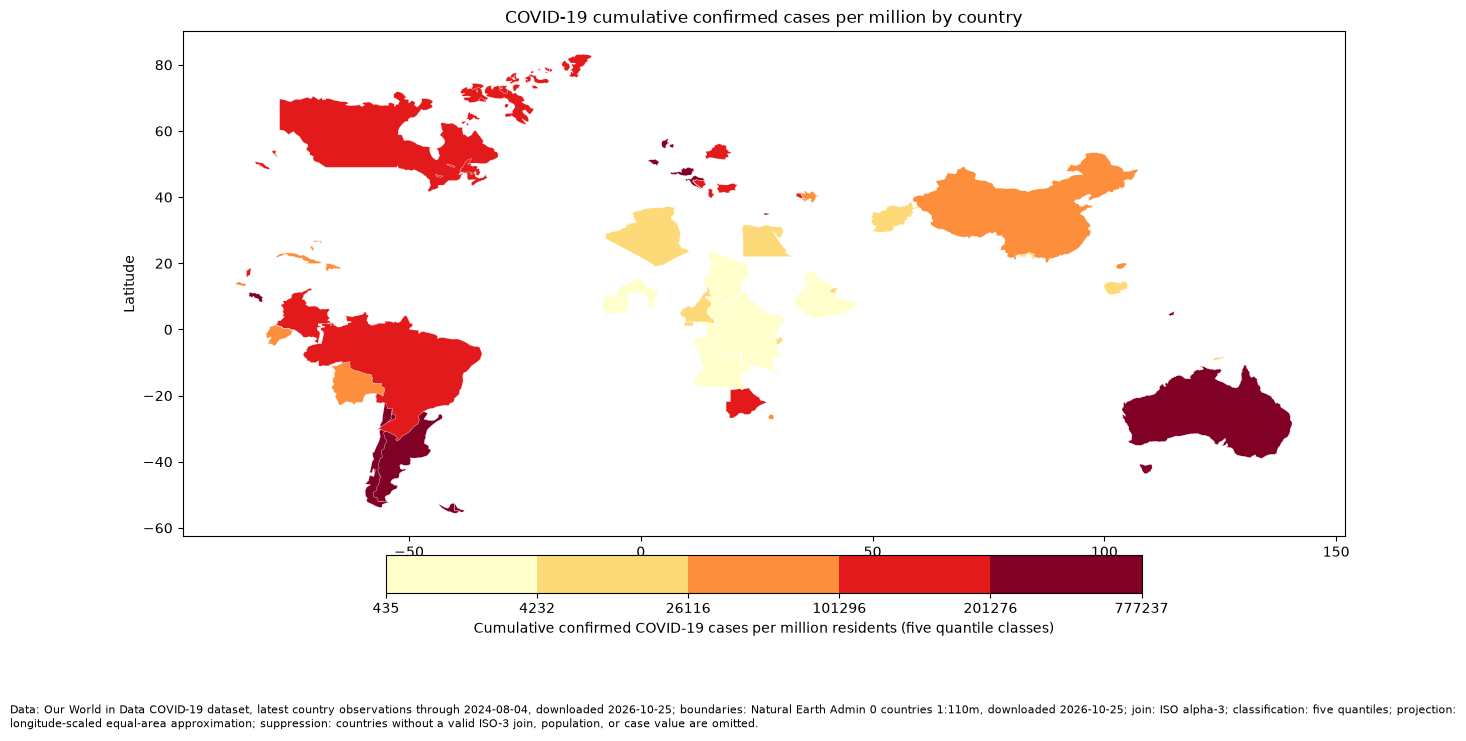

In [3]:
fig,ax=plt.subplots(figsize=(15,8)); cmap='YlOrRd'; norm=BoundaryNorm(breaks,ncolors=plt.get_cmap(cmap).N,clip=True)
value_by_iso=valid.set_index('iso_code').cases_per_million.to_dict()
for iso,f in by_iso.items():
    if iso not in value_by_iso: continue
    color=plt.get_cmap(cmap)(norm(value_by_iso[iso]))
    for ring in rings(f['geometry']):
        xy=project_ring(ring); ax.fill(xy[:,0],xy[:,1],color=color,ec='white',lw=.25)
sm=ScalarMappable(norm=norm,cmap=cmap); sm.set_array([]); cb=fig.colorbar(sm,ax=ax,orientation='horizontal',pad=.03,shrink=.65)
cb.set_label('Cumulative confirmed COVID-19 cases per million residents (five quantile classes)')
ax.set_title('COVID-19 cumulative confirmed cases per million by country')
ax.set_xlabel('Equal-area projected longitude'); ax.set_ylabel('Latitude')
caption=(f'Data: Our World in Data COVID-19 dataset, latest country observations through {valid.date.max().date()}, downloaded {DOWNLOAD_DATE}; '
         f'boundaries: Natural Earth Admin 0 countries 1:110m, downloaded {DOWNLOAD_DATE}; '
         'join: ISO alpha-3; classification: five quantiles; projection: longitude-scaled equal-area approximation; '
         'suppression: countries without a valid ISO-3 join, population, or case value are omitted.')
fig.text(.01,.01,caption,fontsize=8,ha='left',wrap=True)
path=BASE/'F_bonus_normalized_covid_map.png'; fig.savefig(path,dpi=300,bbox_inches='tight'); print('saved',path); plt.show()


## What the raw-count version would have shown

A raw-count map would have highlighted the most populous countries?especially India, the United States, and China?because population size directly drives the number of recorded cases. The normalized map instead compares cumulative confirmed cases per million residents, while still requiring caution about testing, reporting, and pandemic-date differences across countries.


## Sources

- Our World in Data. *COVID-19 dataset*. CSV: https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv. Download date: 2026-10-25.
- Natural Earth. *Admin 0 ? Countries, 1:110m*, GeoJSON. Repository: https://github.com/nvkelso/natural-earth-vector. Download date: 2026-10-25.
